# 14 — Auditorias que não dependem de achar efeito

Mesmo quando o engajamento é ruído, a **composição** da carteira pode ser auditada. Esta parte responde a quatro perguntas de gestão e a uma de método:
1. **Disclosure:** quantos patrocínios têm risco regulatório, e o rótulo aparece no texto?
2. **Fit:** o patrocinador combina com o nicho do creator?
3. **Mercado:** o post fala o idioma da audiência e está numa plataforma que ela consegue abrir?
4. **Duração:** o tamanho importa quando medido na unidade certa (segundos no vídeo, palavras no texto)?
5. **Poder:** em cada subgrupo, qual o menor efeito que daria para ver?

As regras (risco, fit, idioma e plataforma por mercado) são constantes editáveis em `social_insights/audits.py`. Elas vêm do conhecimento de mercado, não deste dataset, e não são parecer jurídico.

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from social_insights import audits

52,214 posts


## 1. Disclosure: risco regulatório por mercado

In [2]:
disc = audits.disclosure_audit(df)
display(Markdown(f"**{disc.verdict}**"))
display(disc.evidence)
for name, table in disc.details.items():
    display(Markdown(f"**{name}**")); display(table)

**47.2% dos posts patrocinados usam disclosure implícito (risco alto em todos os 8 mercados) e 17.2% divulgam só dentro do vídeo (risco médio). Só 2.3% têm um rótulo de publicidade visível no texto, então o rótulo da base não pode ser auditado. Tipo e local do disclosure não mudam o engajamento, então exigir disclosure explícito no texto não tem custo de desempenho.**

,norma,posts,% risco alto,% risco médio,% risco baixo,% com rótulo no texto
audience_location,,,,,,
UK,CAP Code (ASA) / CMA,2885,49.0000,16.4000,34.6000,2.1000
Russia,Lei Federal de Publicidade (marcação),2734,49.0000,17.1000,33.9000,2.2000
USA,FTC Endorsement Guides,2778,47.2000,18.2000,34.6000,2.4000
Brazil,CONAR (Guia de publicidade por influenciadores),2769,47.0000,17.9000,35.1000,2.3000
Germany,UWG §5a,2791,46.7000,15.5000,37.8000,2.0000
Japan,"Lei de prêmios (stealth marketing, 2023)",2753,46.7000,17.7000,35.6000,2.2000
China,Lei de Publicidade (art. 14),2789,46.4000,16.1000,37.5000,2.5000
India,ASCI Influencer Guidelines,2815,45.5000,18.7000,35.8000,2.4000


**Risco por plataforma (%)**

risco,alto,baixo,médio
platform,,,
Bilibili,46.9000,36.2000,16.8000
Instagram,47.6000,35.7000,16.8000
RedNote,47.8000,34.7000,17.5000
TikTok,45.4000,36.8000,17.8000
YouTube,48.2000,34.7000,17.1000


**Rótulo visível no texto × local declarado**

,% com rótulo no texto
disclosure_location,
caption,2.5600
hashtags,2.1200
video,2.0300
orgânicos (referência),2.1300


**Disclosure × engajamento**

,comparação,melhor,pior,diferença melhor−pior (%),p_value,q_value,significativo
0,disclosure_type,explicit,implicit,0.0445,0.1258,0.2516,False
1,disclosure_location,hashtags,caption,0.0665,0.2628,0.2628,False


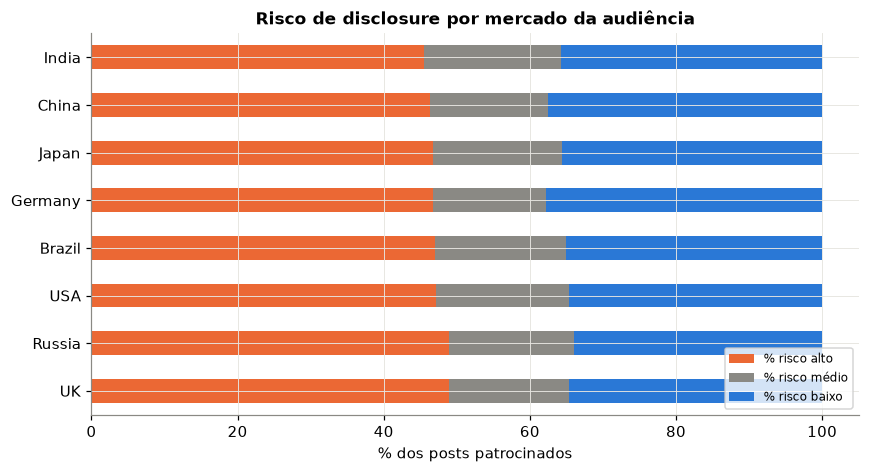

In [3]:
risk = disc.evidence[["% risco alto", "% risco médio", "% risco baixo"]]
ax = risk.plot.barh(stacked=True, figsize=(9, 4.5), color=[plots.ORANGE, plots.GRAY, plots.BLUE])
ax.set_xlabel("% dos posts patrocinados"); ax.set_ylabel(""); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Risco de disclosure por mercado da audiência")
plt.show()

**Leitura:** quase metade dos patrocínios usa disclosure implícito, que não identifica o post como publicidade em nenhum dos 8 mercados. Além disso, o rótulo declarado na base não aparece no texto: os posts com disclosure "em hashtags" têm #ad tanto quanto os orgânicos (~2%). Com dados reais, **o rótulo precisa ser verificável** (#ad/#publi no texto), não só um campo de planilha.

## 2. Fit patrocinador × nicho

In [4]:
fit = audits.sponsor_fit(df)
display(Markdown(f"**{fit.verdict}**"))
display(fit.evidence)
for name, table in fit.details.items():
    display(Markdown(f"**{name}**")); display(table)

**Só 39.9% dos patrocínios estão no nicho do creator (ex.: cosmetics em beauty). No mesmo estrato, patrocínio no nicho não rende mais nem menos neste dataset: fit é critério de marca, não de desempenho, até haver dados reais.**

,diferença,IC95 inf,IC95 sup,diferença (%),p_value,estratos,q_value,significativo
métrica,,,,,,,,
eng_rate_views,-0.0000,-0.0001,0.0001,-0.0003,0.9935,229,0.9935,False
views,-0.5486,-3.1963,2.0992,-0.0054,0.6847,229,0.9935,False


**Mix nicho × patrocinador (%)**

sponsor_category,cosmetics,electronics,fashion,food,gaming,travel
content_category,,,,,,
beauty,16.8000,16.4000,16.4000,17.2000,16.8000,16.4000
lifestyle,16.4000,17.2000,16.5000,17.6000,16.4000,15.9000
tech,16.1000,16.9000,17.2000,16.7000,16.2000,16.8000


**% no nicho por patrocinador**

,% no nicho
sponsor_category,
cosmetics,40.8000
electronics,20.3000
fashion,79.1000
food,40.6000
gaming,19.8000
travel,39.0000


**Leitura:** os patrocinadores estão distribuídos por igual entre os nichos (~1/6 cada), então 60% dos patrocínios ficam fora do nicho (ex.: gaming em beauty). Aqui isso não muda o desempenho. Com dados reais, este é o primeiro filtro de seleção de creator a testar.

## 3. Coerência idioma × mercado × plataforma

In [5]:
mkt = audits.market_coherence(df)
display(Markdown(f"**{mkt.verdict}**"))
display(mkt.evidence)
for name, table in mkt.details.items():
    display(Markdown(f"**{name}**")); display(table)

**Só 22.0% dos posts falam o idioma do mercado da audiência e estão numa plataforma disponível lá. 12.6% miram um mercado onde a plataforma é bloqueada (ex.: Instagram/YouTube na China). 3 de 8 mercados (Brazil, Germany, Russia) não têm nenhum post no próprio idioma. Coerência não muda o resultado aqui, o que confirma que audiência e conteúdo foram sorteados de forma independente. Use como checagem de qualidade dos dados reais.**

,posts,% no idioma do mercado,% em plataforma disponível,% coerente,idiomas do mercado no dataset
audience_location,,,,,
Brazil,6505,0.0000,100.0000,0.0000,nenhum
China,6648,19.4000,40.3000,7.8000,Chinese
Germany,6497,0.0000,100.0000,0.0000,nenhum
India,6484,59.9000,80.1000,48.3000,"English, Hindi"
Japan,6553,10.0000,100.0000,10.0000,Japanese
Russia,6459,0.0000,79.4000,0.0000,nenhum
UK,6570,49.8000,100.0000,49.8000,English
USA,6498,60.2000,100.0000,60.2000,"English, Spanish"


**Plataformas bloqueadas no mercado**

,audience_location,platform,posts
2,China,YouTube,1390
4,Russia,Instagram,1328
0,China,Instagram,1322
3,India,TikTok,1290
1,China,TikTok,1256


**Coerentes × incoerentes**

,coerentes,incoerentes,diferença (%),p_value,q_value,significativo
métrica,,,,,,
eng_rate_views,0.1991,0.1991,0.0021,0.9340,0.9340,False
views,10100.4461,10100.2374,0.0021,0.8427,0.9340,False


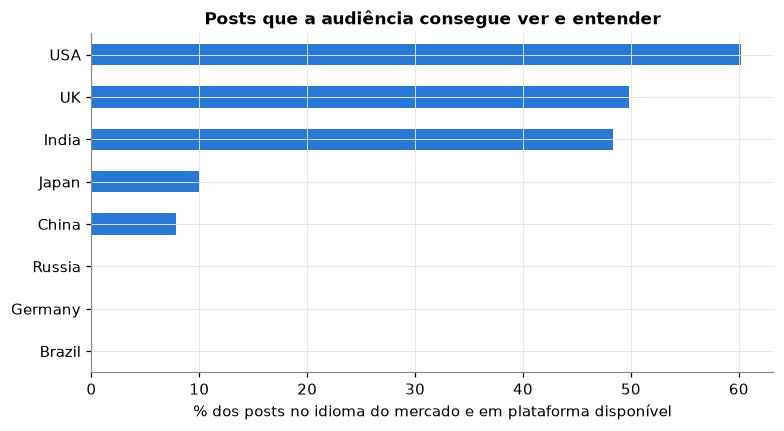

In [6]:
ax = mkt.evidence["% coerente"].sort_values().plot.barh(figsize=(8, 4), color=plots.BLUE)
ax.set_xlabel("% dos posts no idioma do mercado e em plataforma disponível"); ax.set_ylabel("")
ax.set_title("Posts que a audiência consegue ver e entender")
plt.show()

**Leitura:** Brasil, Alemanha e Rússia não têm nenhum post no próprio idioma (não existe português, alemão nem russo na base), e 1 em cada 8 posts mira um mercado onde a plataforma é bloqueada. Isso mostra que audiência e conteúdo foram sorteados de forma independente. Com dados reais, a mesma função vira **checagem de qualidade** e **mapa de cobertura** (quais mercados estão sem conteúdo no idioma).

## 4. Duração na unidade correta

In [7]:
length = audits.length_by_format(df)
display(Markdown(f"**{length.verdict}**"))
display(length.evidence)
for name, table in length.details.items():
    display(Markdown(f"**{name}**")); display(table)

**29.7% dos posts (imagem e misto) têm 'duração' sem unidade definida, e eles ficam fora da análise. Separando vídeo (segundos) e texto (palavras), o tamanho não muda views nem engajamento (|ρ| ≤ 0.018; detectaríamos |ρ| ≥ 0.039). A crença 'conteúdo curto engaja mais' foi testada antes misturando segundos e palavras e deve usar esta versão.**

,formato,unidade,métrica,n,ρ,MDE de ρ,p_value,q_value,significativo
0,video,segundos,views,31500,0.0012,0.0158,0.8304,0.8304,False
1,video,segundos,eng_rate_views,31500,0.0111,0.0158,0.0490,0.1961,False
2,text,palavras,views,5198,-0.0178,0.0389,0.1991,0.3982,False
3,text,palavras,eng_rate_views,5198,0.0104,0.0389,0.4535,0.6047,False


**Distribuição por formato**

,count,min,50%,max,unidade
content_type,,,,,
image,10303.0000,10.0000,173.0000,599.0000,indefinida
mixed,5213.0000,10.0000,175.0000,599.0000,indefinida
text,5198.0000,10.0000,174.0000,599.0000,palavras
video,31500.0000,10.0000,174.0000,599.0000,segundos


**video por faixa (segundos)**

,views (índice),eng_rate_views (índice)
content_length,,
curto (<60 s),99.9900,99.9800
médio (60–180 s),100.0000,99.9700
longo (180–360 s),100.0100,99.9700
muito longo (360+ s),99.9900,100.0800


**text por faixa (palavras)**

,views (índice),eng_rate_views (índice)
content_length,,
curto (<100 palavras),100.0000,100.0000
médio (100–300),100.0100,99.9500
longo (300+),99.9800,100.0600


**Leitura:** imagem e misto têm "duração" de 10 a 599, igual a vídeo e texto, ou seja, o campo não tem significado nesses formatos. Separando segundos (vídeo) e palavras (texto), o tamanho continua sem efeito, e o teste teria poder para ver |ρ| ≥ 0,04. As análises anteriores com `length_bin` (notebooks 02–12, crença "conteúdo curto") misturam unidades e devem ser lidas com essa ressalva.

## 5. Poder estatístico por subgrupo

In [8]:
power = audits.subgroup_power(df)
display(Markdown(f"**{power.verdict}**"))
display(power.evidence.head(15))

**Para todo subgrupo, mostramos o menor efeito que daria para ver (MDE, 80% de poder). O mais fraco é follower_tier = nano (<10K) (n = 454), com MDE de 0.32% em eng_rate_views. Todas detectariam um efeito de 5%, então 'equivalente' aqui quer dizer 'sem diferença relevante', não 'sem dados'.**

,dimensão,valor,métrica,n,diferença observada (%),MDE (%),conclusivo
0,follower_tier,nano (<10K),eng_rate_views,454,-0.0378,0.3230,True
1,follower_tier,micro (10–50K),eng_rate_views,2110,0.0226,0.1523,True
2,follower_tier,mid (50–100K),eng_rate_views,2596,0.0363,0.1380,True
3,audience_age_distribution,50+,eng_rate_views,2650,0.0332,0.1366,True
4,follower_tier,nano (<10K),views,454,-0.0970,0.1308,True
5,language,Japanese,eng_rate_views,5177,0.0342,0.1004,True
6,content_type,text,eng_rate_views,5198,0.0537,0.1002,True
7,content_type,mixed,eng_rate_views,5213,0.0477,0.1000,True
8,language,Spanish,eng_rate_views,5227,0.0367,0.0999,True
9,audience_gender_distribution,unknown,eng_rate_views,5235,0.0011,0.0999,True


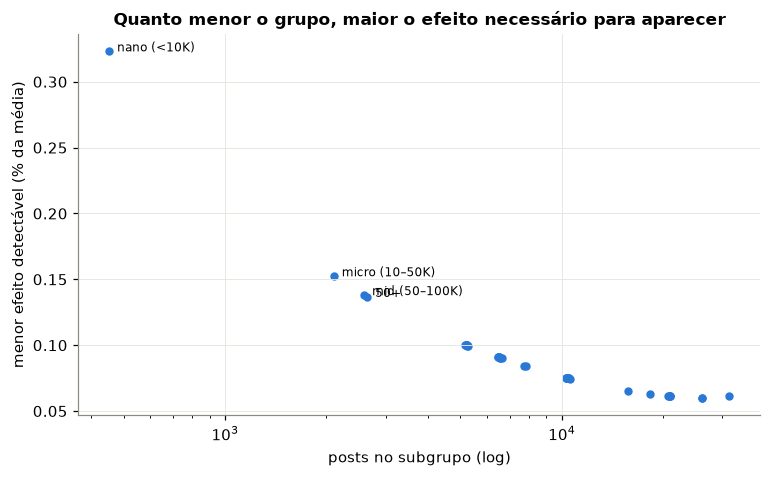

In [9]:
eng = power.evidence.query("métrica == @audits.ENGAGEMENT")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(eng["n"], eng["MDE (%)"], color=plots.BLUE, s=20)
for _, r in eng.nlargest(4, "MDE (%)").iterrows():
    ax.annotate(r["valor"], (r["n"], r["MDE (%)"]), fontsize=8, xytext=(5, 0), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("posts no subgrupo (log)"); ax.set_ylabel("menor efeito detectável (% da média)")
ax.set_title("Quanto menor o grupo, maior o efeito necessário para aparecer")
plt.show()

**Leitura:** até o menor grupo (nano, 454 posts) detectaria uma diferença de 0,3% no engajamento. Então "equivalente" significa "sem diferença relevante", não "sem dados". Com dados reais (variância muito maior que a do Poisson), esta tabela mostra onde ainda faltam posts antes de decidir.

## Conclusões
1. **Compliance é a ação mais segura desta entrega:** quase metade dos patrocínios tem disclosure implícito. Exigir rótulo explícito no texto não custa engajamento.
2. **O rótulo de disclosure da base não é auditável**, porque não aparece no texto. Com dados reais, verificar no próprio post.
3. **Fit e coerência de mercado** não mudam o desempenho aqui (dados sorteados), mas expõem lacunas de carteira: 60% dos patrocínios fora do nicho e 3 mercados sem conteúdo no idioma.
4. **Duração** só tem significado em vídeo e texto, e não tem efeito em nenhum dos dois.
5. **Poder:** todos os "sem efeito" desta entrega são conclusivos para efeitos de 5% ou mais.